# skf-ds-home-assignment

# Industrial Motor Temperature Anomaly Detection

## Problem Definition

- **Goal:** Assign an `alarm` or `no_alarm` label to every processed temperature measurement.

- **Input:** Two years of timestamped motor-temperature readings stored in daily Parquet files.

- **Available labels:** The dataset contains no confirmed anomaly labels, and the motor is assumed to operate normally most of the time.

- **Target behavior:** A consistent, gradual increase in temperature.

- **Prediction constraint:** Each new row should be assigned as alarm or not 

- **Non-target behavior:** Isolated temperature spikes, sensor glitches, or short-lived deviations should not by themselves trigger a gradual-trend alarm. They may be reported separately as data-quality warnings or signals\features.

- **Evaluation constraint:** Because confirmed anomaly labels are unavailable, the analysis should reveal the saught for pattern to detect and build features for either simple statistics thresholds or unsupervised techniques



In [90]:
import pandas as pd 
import numpy as np 
import glob

import matplotlib as plt
import plotly.express as px

# Part 1: Exploratory Data Analysis (EDA)

## 1. Load and inspect the data

Load all daily partitions into one table, then verify the basic schema and data quality before interpreting patterns.


In [91]:
files = sorted(glob.glob("../Machine_*/Stream_*/*/data.parquet")) # sort according to date strings
df = pd.concat([pd.read_parquet(file) for file in files], ignore_index=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6503 entries, 0 to 6502
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   timestamp  6503 non-null   datetime64[ns]
 1   temp_c     6503 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 101.7 KB


In [92]:
data_quality_summary = pd.Series(
    {
        "source_file_count": len(files),
        "row_count": len(df),
        "duplicate_timestamps": df["timestamp"].duplicated().sum(),
        "missing_timestamps": df["timestamp"].isna().sum(),
        "missing_temperatures": df["temp_c"].isna().sum(),
        "timestamps_sorted": df["timestamp"].is_monotonic_increasing,
    }
)

display(data_quality_summary)


source_file_count        700
row_count               6503
duplicate_timestamps       0
missing_timestamps         0
missing_temperatures       0
timestamps_sorted       True
dtype: object

In [93]:
df.describe()

,timestamp,temp_c
count,6503,6503.000000
mean,2023-12-30 11:14:33.566046208,21.803324
min,2023-01-01 00:00:00,8.412104
25%,2023-06-24 21:00:00,16.221513
50%,2024-01-06 08:00:00,19.213230
75%,2024-06-30 13:30:00,22.812844
max,2024-12-30 23:00:00,368.838862
std,NaN,20.164273


The dataset contains 6,503 timestamped readings with no missing values. The large gap between the median and maximum temperature suggests that robust summaries will be more informative than the mean alone.


## 2. Sampling coverage and gaps

Understand how often the sensor is observed before creating rolling or rate-based features.


In [94]:
full_range = pd.date_range(df.timestamp.min().date(), df.timestamp.max().date(), freq="D")
daily_counts = df.groupby(df.timestamp.dt.date).size().reindex(full_range.date, fill_value=0)
days_with_data = daily_counts[daily_counts > 0]
print(f'Days with data { len(days_with_data)} vs Total days { len(daily_counts)}')
print (f'Median daily measurments {df.groupby(df.timestamp.dt.date).size().median()} ')

Days with data 700 vs Total days 730
Median daily measurments 9.0 


In [95]:
ordered_timestamps = df[["timestamp"]].sort_values("timestamp").copy()
ordered_timestamps["previous_timestamp"] = ordered_timestamps["timestamp"].shift()
ordered_timestamps["gap_hours"] = (
    ordered_timestamps["timestamp"].diff().dt.total_seconds() / 3600
)

ordered_timestamps.loc[ordered_timestamps["gap_hours"] > 24,["previous_timestamp", "timestamp", "gap_hours"],]



,previous_timestamp,timestamp,gap_hours
2961,2023-11-16 21:00:00,2023-12-07 02:00:00,485.0
4908,2024-07-03 23:00:00,2024-07-14 02:00:00,243.0


<Axes: xlabel='timestamp'>

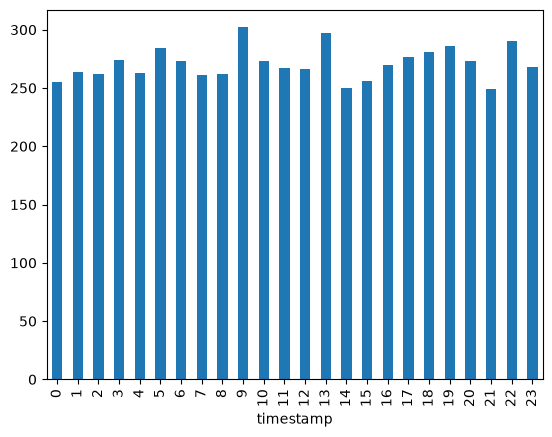

In [96]:
df.timestamp.dt.hour.value_counts().sort_index().plot(kind="bar")

There are 700 days with data out of 730 and a median of nine readings per observed day. Measurement counts are fairly balanced across hours, but the long gaps should be treated as breaks in continuity rather than ordinary missing rows.


## 3. Temperature distribution

Inspect the main operating range and determine whether high readings form isolated tails or a distinct group.


In [97]:
fig = px.histogram(
    df, x="temp_c", nbins=100,
    marginal="box",
    title="Temperature Distribution",
    labels={"temp_c": "Temperature (°C)"},
)
fig.update_layout(yaxis_title="Count")
fig.show()

### Initial distribution observations

- Most readings occupy a compact range below approximately 47°C.
- A separate group appears between approximately 170°C and 233°C, with one additional reading near 369°C.
- The separation is worth investigating, but it does not yet establish whether these readings are physical events, sensor artifacts, or another regime. No rows are removed at this stage.


## 4. Temperature over time

A timeline helps separate persistent level changes from short-lived high readings and shows where data gaps interrupt the sequence.


In [98]:
fig = px.line(df,x="timestamp", y="temp_c", title="Temperture machine timeline")
fig.show()

The high readings occur at multiple points across the timeline. The background temperature also changes over time, so both transient episodes and slower trends remain plausible behaviors to investigate.


## 5. Extreme-reading audit

Use the empty range between the main distribution and high-value group as an exploratory separator—not as a final alarm threshold.


In [99]:
sorted_temperatures = (
    df[["timestamp", "temp_c"]]
    .sort_values("temp_c")
    .reset_index(drop=True)
)

sorted_temperatures["previous_temp_c"] = sorted_temperatures["temp_c"].shift()
sorted_temperatures["gap_c"] = (
    sorted_temperatures["temp_c"]
    - sorted_temperatures["previous_temp_c"]
)

display (
    sorted_temperatures
    .nlargest(10, "gap_c")
    [["previous_temp_c", "temp_c", "gap_c"]]
)

# Exploratory separator only—not a model threshold.
extreme_threshold_c = 100.0

extreme_measurements = df.loc[
    df["temp_c"] > extreme_threshold_c
].copy()

extreme_summary = pd.Series(
    {
        "measurement_count": len(extreme_measurements),
        "percentage_of_data": 100 * len(extreme_measurements) / len(df),
        "affected_days": extreme_measurements["timestamp"].dt.date.nunique(),
        "minimum_temp_c": extreme_measurements["temp_c"].min(),
        "median_temp_c": extreme_measurements["temp_c"].median(),
        "maximum_temp_c": extreme_measurements["temp_c"].max(),
    }
)

display(extreme_summary)

display(
    extreme_measurements
    .assign(date=extreme_measurements["timestamp"].dt.date)
    .groupby("date")
    .agg(
        measurement_count=("temp_c", "size"),
        minimum_temp_c=("temp_c", "min"),
        maximum_temp_c=("temp_c", "max"),
    )
    .sort_values(
        ["measurement_count", "maximum_temp_c"],
        ascending=False,
    )
    .head(15)
)

,previous_temp_c,temp_c,gap_c
6502,232.778364,368.838862,136.060498
6430,47.167564,170.475797,123.308233
6495,218.181639,223.132856,4.951218
6444,184.132394,187.762699,3.630305
6499,227.294779,230.716068,3.421289
6428,43.349358,46.741306,3.391948
6497,224.272316,227.006923,2.734607
6438,177.574310,179.770588,2.196278
6437,175.379588,177.574310,2.194722
6442,182.064110,184.114997,2.050887


measurement_count      73.000000
percentage_of_data      1.122559
affected_days          50.000000
minimum_temp_c        170.475797
median_temp_c         202.822778
maximum_temp_c        368.838862
dtype: float64

,measurement_count,minimum_temp_c,maximum_temp_c
date,,,
2024-11-21,3,195.332263,368.838862
2024-12-06,2,232.167412,232.778364
2024-12-16,2,227.006923,230.716068
2024-06-05,2,210.927304,215.749886
2024-11-06,2,212.641502,215.498789
2024-02-09,2,210.041392,213.592412
2024-12-02,2,211.542696,212.092741
2024-06-04,2,210.790417,211.950436
2024-01-25,2,208.169581,211.232401


In [100]:
day = pd.Timestamp("2023-09-23").date()
df[df["timestamp"].dt.date == day].sort_values("timestamp")

,timestamp,temp_c
2463,2023-09-23 00:00:00,15.022868
2464,2023-09-23 02:00:00,206.886573
2465,2023-09-23 03:00:00,206.681769
2466,2023-09-23 04:00:00,16.703547
2467,2023-09-23 08:00:00,22.234708
2468,2023-09-23 09:00:00,21.507102
2469,2023-09-23 13:00:00,21.603989
2470,2023-09-23 17:00:00,21.533443
2471,2023-09-23 18:00:00,20.234567
2472,2023-09-23 21:00:00,18.300155


In [101]:
extreme_threshold_c = 100  # natural gap in the sorted-value diffs above: 47.2 -> 170.5

The 73 readings above 100°C represent about 1.12% of the data and occur on 50 days. Their clear separation from the main range supports analyzing them as a distinct behavior, while retaining the original values until their temporal context is understood.


###  Extreme reading rate by hour

Raw hourly counts describe coverage. Dividing extreme counts by all readings at each hour asks whether the high-value group is concentrated at particular times of day.


In [102]:
hourly_extreme_rate = (
    df.assign(
        hour=df["timestamp"].dt.hour,
        is_extreme=df["temp_c"] > extreme_threshold_c,
    )
    .groupby("hour")
    .agg(
        total_readings=("temp_c", "size"),
        extreme_readings=("is_extreme", "sum"),
    )
)

hourly_extreme_rate["extreme_rate_pct"] = (
    100
    * hourly_extreme_rate["extreme_readings"]
    / hourly_extreme_rate["total_readings"]
)

display(hourly_extreme_rate)

fig = px.bar(
    hourly_extreme_rate.reset_index(),
    x="hour",
    y="extreme_rate_pct",
    title="Extreme-Reading Rate by Hour of Day",
    labels={"hour": "Hour of day", "extreme_rate_pct": "Extreme readings (%)"},
)
fig.show()


,total_readings,extreme_readings,extreme_rate_pct
hour,,,
0,255,0,0.000000
1,264,3,1.136364
2,262,5,1.908397
3,274,7,2.554745
4,263,4,1.520913
5,284,0,0.000000
6,273,4,1.465201
7,261,3,1.149425
8,262,2,0.763359


Apperance rate is not ignificantly different at any of the hours, especially considering the sample group size comparing the noraml group

### Group extreme rows into episodes

Consecutive high readings may represent one short episode rather than independent anomalies. A four-hour boundary follows the observed short-gap sampling pattern and remains exploratory.


In [103]:
df_sorted = df.sort_values("timestamp").reset_index(drop=True).copy()
df_sorted["time_gap_hours"] = (
    df_sorted["timestamp"].diff().dt.total_seconds() / 3600
)
df_sorted["is_extreme"] = df_sorted["temp_c"] > extreme_threshold_c

previous_was_extreme = df_sorted["is_extreme"].shift(fill_value=False)
df_sorted["starts_extreme_episode"] = (
    df_sorted["is_extreme"]
    & (
        ~previous_was_extreme
        | (df_sorted["time_gap_hours"] > 4)
    )
)
df_sorted["extreme_episode_id"] = (
    df_sorted["starts_extreme_episode"].cumsum().where(df_sorted["is_extreme"])
)

extreme_episodes = (
    df_sorted.loc[df_sorted["is_extreme"]]
    .groupby("extreme_episode_id")
    .agg(
        start_time=("timestamp", "min"),
        end_time=("timestamp", "max"),
        measurement_count=("temp_c", "size"),
        minimum_temp_c=("temp_c", "min"),
        maximum_temp_c=("temp_c", "max"),
    )
)

display(
    extreme_episodes["measurement_count"]
    .value_counts()
    .sort_index()
    .rename("episode_count")
)
display(extreme_episodes.head(10))


measurement_count
1    28
2    21
3     1
Name: episode_count, dtype: int64

,start_time,end_time,measurement_count,minimum_temp_c,maximum_temp_c
extreme_episode_id,,,,,
1.0,2023-03-03 08:00:00,2023-03-03 12:00:00,2,187.762699,189.007695
2.0,2023-03-15 23:00:00,2023-03-15 23:00:00,1,175.379588,175.379588
3.0,2023-03-28 07:00:00,2023-03-28 07:00:00,1,180.611409,180.611409
4.0,2023-05-05 01:00:00,2023-05-05 01:00:00,1,199.605197,199.605197
5.0,2023-05-31 19:00:00,2023-05-31 19:00:00,1,205.526147,205.526147
6.0,2023-07-01 09:00:00,2023-07-01 09:00:00,1,177.574310,177.574310
7.0,2023-07-06 20:00:00,2023-07-06 20:00:00,1,218.181639,218.181639
8.0,2023-07-20 09:00:00,2023-07-20 09:00:00,1,182.064110,182.064110
9.0,2023-07-26 03:00:00,2023-07-26 03:00:00,1,190.085819,190.085819


## 6. Short-term temperature change

Normalizing temperature differences by elapsed time is useful for identifying abrupt transitions under irregular sampling. It is a diagnostic for jumps, not yet a measure of the requested gradual trend.


In [104]:
df_sorted = df.sort_values("timestamp").copy()
df_sorted["temp_delta"] = df_sorted["temp_c"].diff()

df_sorted["time_gap_hours"] = df_sorted["timestamp"].diff().dt.total_seconds() / 3600
df_sorted["rate_c_per_hours"] = df_sorted["temp_delta"] / df_sorted["time_gap_hours"]

df_sorted["rate_c_per_hours"].describe()


count    6502.000000
mean       -0.077140
std        11.410161
min      -189.978222
25%        -0.827137
50%         0.002485
75%         0.826466
max       195.179244
Name: rate_c_per_hours, dtype: float64

In [105]:
fig = px.histogram(
    df_sorted, x="rate_c_per_hours", nbins=100,
    marginal="box",
    title="Temperature Jump Normalized on Time Gap Distribution (diff/time from last measurment)",
    labels={"rate_c_per_hours": "Temperature change rate (°C/hour)"},
)
fig.update_layout(yaxis_title="Count")
fig.show()

The distribution is centered near zero but has large positive and negative tails. These tails may reflect entry into and recovery from extreme episodes. Before interpreting them physically, compare transitions involving extreme readings with ordinary transitions and exclude long gaps where continuity is unknown.


## 7. Daily (diurnal) cycle check

Before treating any multi-day rise as a developing fault, check whether temperature simply follows a daily cycle (e.g. ambient/operational heating through the day). Extreme readings are excluded here so they don't distort the normal-range pattern.

In [106]:
normal_range = df.loc[df["temp_c"] <= extreme_threshold_c].copy()
normal_range["hour"] = normal_range["timestamp"].dt.hour

hourly_temp = normal_range.groupby("hour")["temp_c"].agg(["mean", "median", "std", "count"])
print(f'Hourly mean range: {hourly_temp["mean"].max() - hourly_temp["mean"].min():.1f}°C')

fig = px.line(
    hourly_temp.reset_index(), x="hour", y="mean",
    title="Mean Temperature by Hour of Day (extreme readings excluded)",
    labels={"hour": "Hour of day", "mean": "Mean temperature (°C)"},
)
fig.show()

Hourly mean range: 8.0°C


A clear diurnal cycle is present: mean temperature dips to about 15.8°C overnight (01:00-03:00) and peaks near 23.8°C in early afternoon (13:00), an ~8°C daily swing. This is a separate, faster-period cycle from the annual seasonal pattern modeled in section 8 below — both are real, recurring effects unrelated to the developing-fault behavior being targeted. Trend features (rolling mean/slope) should be computed over daily or longer windows, or detrended by hour, so this normal daily cycle isn't mistaken for the gradual multi-day rise the model is meant to catch.

## Interim findings and next questions

- The observed schema is simple and contains no null values; duplicate and ordering checks remain explicit.
- Sampling is sparse but reasonably distributed across hours, with two long breaks in continuity.
- High readings form a clearly separated group, but their meaning is not yet known and they are retained.
- Next, examine values immediately before and after each extreme episode, then analyze the slower background trend with robust rolling summaries.


## 8. Isolating the developing issue

The case description states the fault should appear as a *consistent, gradual increase* in temperature, which is a different signature from the isolated high-value readings audited above. This section separates the two: exclude the extreme group (`temp_c > extreme_threshold_c`) and look for a slow drift in what remains.

In [107]:
# Fit a simple annual cosine curve to the *healthy* months (Jan-Oct, both years) only,
# so the fault period itself can't bias what "expected" looks like.
healthy = df[(df.temp_c <= extreme_threshold_c) & (df.timestamp.dt.month <= 10)]
doy = healthy.timestamp.dt.dayofyear.to_numpy()
X = np.column_stack([np.ones_like(doy, dtype=float), np.cos(2*np.pi*doy/365), np.sin(2*np.pi*doy/365)])
coef, *_ = np.linalg.lstsq(X, healthy.temp_c.to_numpy(), rcond=None)

plot_df = df.copy()
plot_doy = plot_df.timestamp.dt.dayofyear.to_numpy()
Xp = np.column_stack([np.ones_like(plot_doy, dtype=float), np.cos(2*np.pi*plot_doy/365), np.sin(2*np.pi*plot_doy/365)])
plot_df["seasonal_expected_c"] = Xp @ coef

fig = px.line(
    plot_df, x="timestamp", y=["temp_c", "seasonal_expected_c"],
    title="Temperature vs. seasonal expectation",
    labels={"value": "Temperature (\u00b0C)", "variable": ""},
)
fig.show()

The seasonal line is a smooth annual cosine fit fitted only on the healthy Jan-Oct readings, then extrapolated across the full year. It represents what temperature is expected purely from time of year, with no suspected fault. Actual readings track it closely most of the time. The two places they pull away are the Nov 2023 episode (temporary, closes back to the line after the gap) and Nov-Dec 2024 (opens up and keeps widening through the end of the data).

Nov-Dec were left out of the fit because that's precisely the window under investigation: both years diverge from the rest of the year there (section 8 below), and 2024 never returns to baseline. Including it would let the fault shape the "healthy" reference, hiding the anomaly it's meant to detect.

In [108]:
baseline = df[df.temp_c <= extreme_threshold_c].set_index("timestamp")
monthly_median = (
    baseline["temp_c"]
    .resample("MS")
    .median()
    .rename("median_temp_c")
)
monthly_median.to_frame()

,median_temp_c
timestamp,
2023-01-01,14.895912
2023-02-01,15.157363
2023-03-01,16.786967
2023-04-01,17.988964
2023-05-01,19.646467
2023-06-01,20.701694
2023-07-01,21.095595
2023-08-01,20.307849
2023-09-01,19.542743


Both years show the same shape from January through October: an increase from ± 15°C to 20°C that tracks with the season, nothing unusual. Late in each year the two years diverge, which is a signal to examine.

In [109]:
weekly_2023_tail = baseline.loc["2023-10-01":"2023-12-31", "temp_c"].resample("W").median()
weekly_2024_tail = baseline.loc["2024-10-01":, "temp_c"].resample("W").median()

print("2023 Oct-Dec weekly median:")
display(weekly_2023_tail)
print("2024 Oct-end weekly median:")
display(weekly_2024_tail)

2023 Oct-Dec weekly median:


timestamp
2023-10-01    19.786642
2023-10-08    19.347160
2023-10-15    19.795112
2023-10-22    22.586122
2023-10-29    24.594934
2023-11-05    26.320837
2023-11-12    29.577165
2023-11-19    32.631935
2023-11-26          NaN
2023-12-03          NaN
2023-12-10    15.497850
2023-12-17    16.187444
2023-12-24    15.567511
2023-12-31    15.186033
Freq: W-SUN, Name: temp_c, dtype: float64

2024 Oct-end weekly median:


timestamp
2024-10-06    18.201408
2024-10-13    18.196985
2024-10-20    19.782566
2024-10-27    19.973717
2024-11-03    22.452405
2024-11-10    24.101044
2024-11-17    26.201116
2024-11-24    26.219379
2024-12-01    27.915195
2024-12-08    29.598528
2024-12-15    31.788095
2024-12-22    32.466502
2024-12-29    33.844808
2025-01-05    34.191006
Freq: W-SUN, Name: temp_c, dtype: float64

**2023:** the baseline climbs from ~20°C (Oct 1) to ~33°C (Nov 19), then the sensor stops reporting for about three weeks (the long gap already flagged in section 2), and when readings resume on 2023-12-07 the baseline is back down at ~13-15°C, consistent with a possible repair or reset during the gap.

**2024:** the same seasonal climb starts on the same schedule, but it does not reset. It keeps rising every week through the end of the dataset (34°C on the last recorded week), with no gap and no recovery. This is the pattern the assignment describes: a *consistent, gradual increase* that is still active when the data ends.

The 2023 episode is possibly a useful reference case. 

In [110]:
day = pd.Timestamp("2024-07-13").date()
df[df["timestamp"].dt.date == day].sort_values("timestamp")

,timestamp,temp_c


In [111]:
gap_starts = df[["timestamp"]].assign(gap_hours=df["timestamp"].diff().dt.total_seconds()/3600)
print("All gaps > 24h:")
display(gap_starts[gap_starts.gap_hours > 24])

print("Last 3 readings before the July 2024 gap, first 3 after:")
display(df[(df.timestamp >= "2024-07-03 12:00") & (df.timestamp <= "2024-07-14 08:00")])


All gaps > 24h:


,timestamp,gap_hours
2961,2023-12-07 02:00:00,485.0
4908,2024-07-14 02:00:00,243.0


Last 3 readings before the July 2024 gap, first 3 after:


,timestamp,temp_c
4904,2024-07-03 12:00:00,25.607010
4905,2024-07-03 16:00:00,25.302097
4906,2024-07-03 20:00:00,19.070450
4907,2024-07-03 23:00:00,17.818610
4908,2024-07-14 02:00:00,17.374189
4909,2024-07-14 03:00:00,18.368201
4910,2024-07-14 07:00:00,18.854162
4911,2024-07-14 08:00:00,22.850093


There is a second gap, in July 2024, that looks superficially similar (10 days missing) but behaves differently: temperature right before it is ~18°C flat, ordinary summer range, no ramp and it resumes at ~17-23°C, the same normal range. Unlike the Dec 2023 gap, there is no climb beforehand and no step-change after.

**Decision:** treat the July 2024 gap as an unrelated data-continuity interruption (possibly routine maintenance or a collection outage), not a fault related event, and do not fold it into the trend model. This is an assumption, not an established fact .

In [112]:
extreme_by_month = (
    df[df.temp_c > extreme_threshold_c]
    .assign(month=lambda d: d["timestamp"].dt.to_period("M"))
    .groupby("month")["temp_c"]
    .agg(count="count", mean_c="mean", max_c="max")
)
extreme_by_month.tail(6)

,count,mean_c,max_c
month,,,
2024-07,1,223.132856,223.132856
2024-08,3,196.217867,206.959077
2024-09,1,201.480196,201.480196
2024-10,4,193.531448,200.090603
2024-11,8,226.518306,368.838862
2024-12,8,220.402427,232.778364


Nov–Dec 2024 stand out in both count (8 each vs. 1–6 elsewhere) and severity (mean 226°C/220°C, including the dataset's max of 369°C), right as the baseline trend also diverges. That co-movement argues these aren't independent noise but a symptom of the same escalating fault so rolling extreme-event rate and rolling max should be carried forward as features alongside the baseline-deviation signal, not treated separately.

# Part 2: Feature Engineering & Model Selection

A note on scope: the alarm rule explored below is our own working definition, not one set by the client. Ideally the machine technicians/operators who know this motor would define what counts as an alarm-worthy pattern. Until that input is available, we are exploring whether early, consistent identification looks possible from the data alone — any thresholds or rules here should be treated as a starting hypothesis to verify with them, not a final answer.

We are also still assuming, per the case description, that this gradual temperature rise is the developing issue we are meant to flag. We proceed on that assumption, but it has not been independently confirmed.

## Alarm definition (working hypothesis)

Building on Part 1, a candidate definition:

1. **Smooth out the daily cycle** — aggregate to daily (or coarser) so the ~8°C diurnal swing from section 7 is not read as drift.
2. **Compare against the seasonal reference** — use `actual - seasonal_expected` from section 8 as a residual, so a normal warm summer does not look like a fault.
3. **Require the residual to persist** — per the problem definition, an isolated spike should not trigger this on its own, so the rule would only turn on once the residual stays above a threshold for several consecutive days, not a single reading.

Threshold and required duration are not settled yet and would need to be checked, not assumed: roughly, whether this turns on during both the 2023 and 2024 climbs and turns back off after the 2023 reset. Given the assumptions noted above, this should be read as a starting point to validate and revise, not a finished detector.